# Exploratory Data Analysis (EDA) - Heart Disease Prediction

In this notebook, we will explore the cleaned heart disease dataset to understand the patterns, distributions, and relationships among variables.  
EDA helps in identifying trends, outliers, and data quality issues and guides us in selecting the right features for modeling.

---

### ✅ Goals of this Notebook:
- Understand the structure and distribution of the dataset
- Analyze numerical and categorical features
- Identify correlations with the target variable
- Visualize feature relationships

Let's begin by loading the cleaned dataset.


## Import Required Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('E:/Heart_Disease_Predictor/data/processed/heart_disease_cleaned.csv')

### Dataset Overview

The dataset has been cleaned in the previous step. It contains no missing values and includes appropriate column names as per the UCI documentation.


In [36]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [37]:
print('shape:', df.shape)
print('\ncolumns:', df.columns.tolist())

shape: (303, 14)

columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


### 🎯 Target Class Distribution

After cleaning and converting the multi-class target to binary (`0 = No Heart Disease`, `1 = Heart Disease`), we visualize the class distribution.  
This helps us understand if the data is **imbalanced**, which is important before model training.

In [38]:
df['target'].value_counts()

target
0    164
1    139
Name: count, dtype: int64

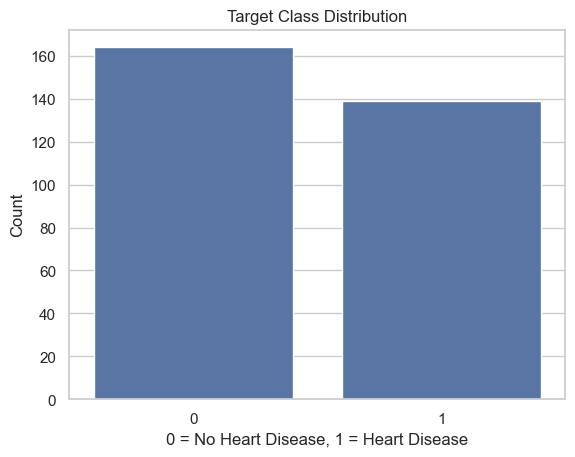

In [39]:
sns.set_theme(style='whitegrid')
sns.countplot(x='target', data=df)
plt.title('Target Class Distribution')
plt.xlabel('0 = No Heart Disease, 1 = Heart Disease')
plt.ylabel('Count')
plt.show()

### Insights from Target Class Distribution

- The target variable has two classes:
  - `0` → No Heart Disease
  - `1` → Presence of Heart Disease

- As observed in the plot:
  - Class `0` has slightly more samples than Class `1`
  - The class distribution is approximately:
    - **55% No Heart Disease**
    - **45% Heart Disease**

#### Conclusion:
- The dataset is **fairly balanced**, which is ideal for model training.
- There's **no immediate need for resampling techniques** like SMOTE or class weighting.
- We can proceed with common classification models (e.g., Logistic Regression, Random Forest, XGBoost) without worrying about severe class imbalance.

---

### Univariate Analysis – Numerical Features

We examine the distribution of key continuous variables such as `age`, `chol`, `trestbps`, `oldpeak` and `thalach`.  
This helps us identify outliers, skewness, and overall patterns in patient health metrics.

 - age
 - trestbps (resting blood pressure)
 - chol (cholesterol)
 - thalach (max heart rate achieved)
 - oldpeak (ST depression)

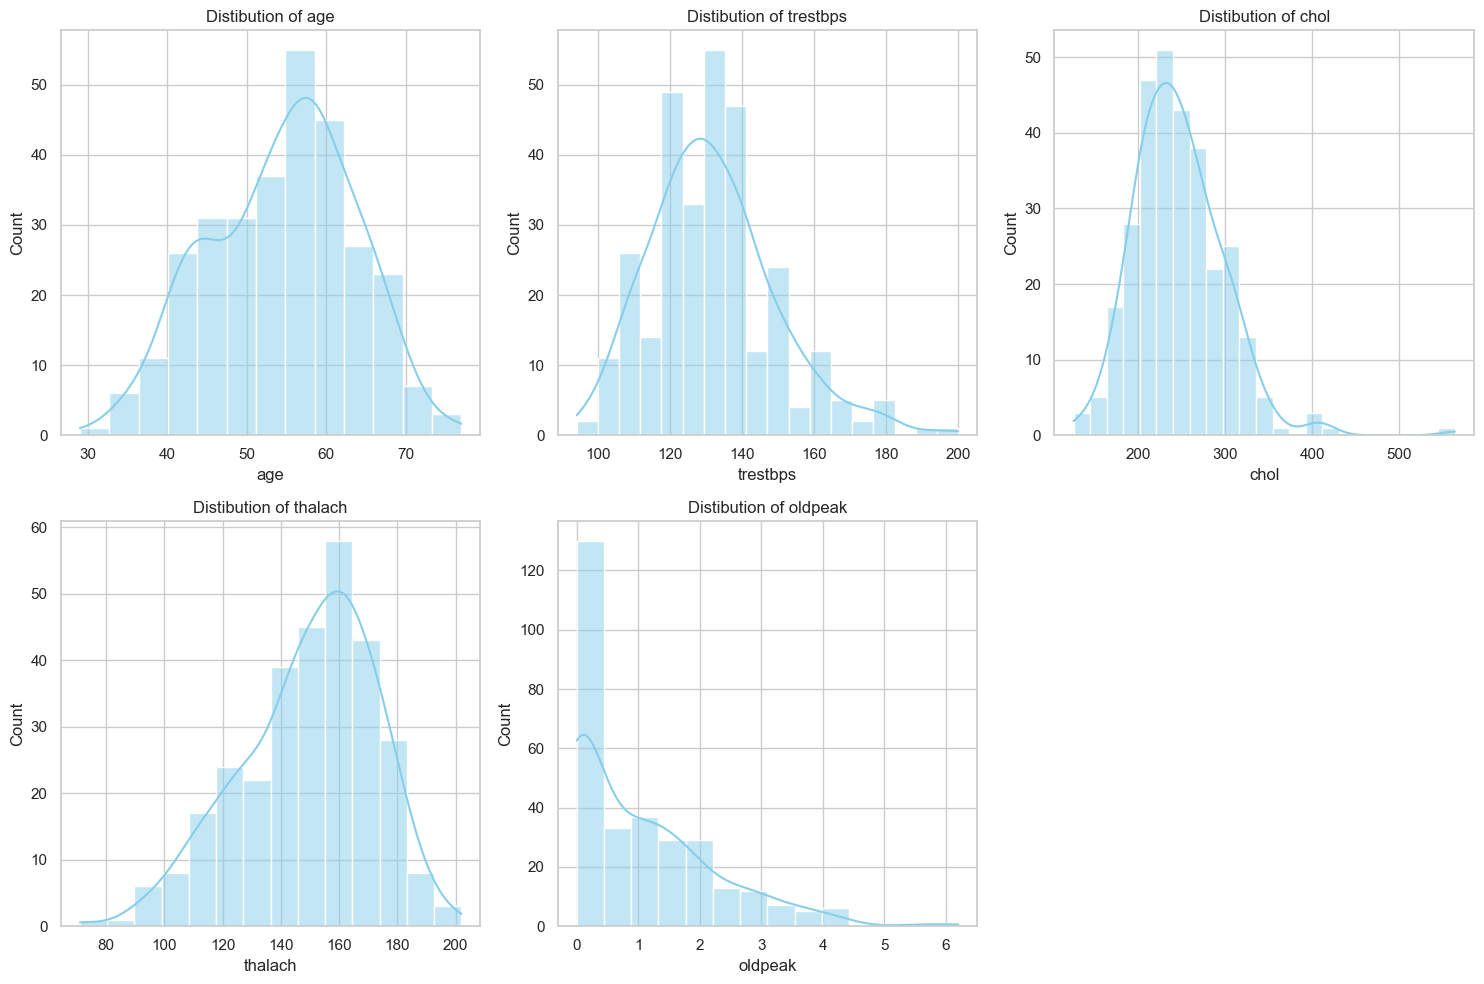

In [40]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

plt.figure(figsize=(15,10))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i+1)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Distibution of {col}')
plt.tight_layout()
plt.show()

### Insights

1. Age:

 - The age distribution is roughly normal, with most patients aged between 50 and 60.

 - This indicates that heart disease is more common in middle-aged individuals.

2. Resting Blood Pressure (trestbps):

 - Distribution is slightly right-skewed, centering around 130–140 mmHg.

 - Some patients have high resting BP (>160), which could be a risk factor.

3. Cholesterol (chol):

 - The distribution is positively skewed with a few outliers above 400 mg/dl.

 - These outliers may indicate hypercholesterolemia, a key heart risk.

4. Maximum Heart Rate Achieved (thalach):

 - Appears normally distributed, peaking around 150–170 bpm.

 - A good indicator of cardiovascular fitness or stress response.

5. Oldpeak (ST depression):

 - Heavily right-skewed, with most values between 0 and 1.

 - Higher oldpeak values could suggest exercise-induced ischemia.

---

### Visualize Distribution of Categorical Features

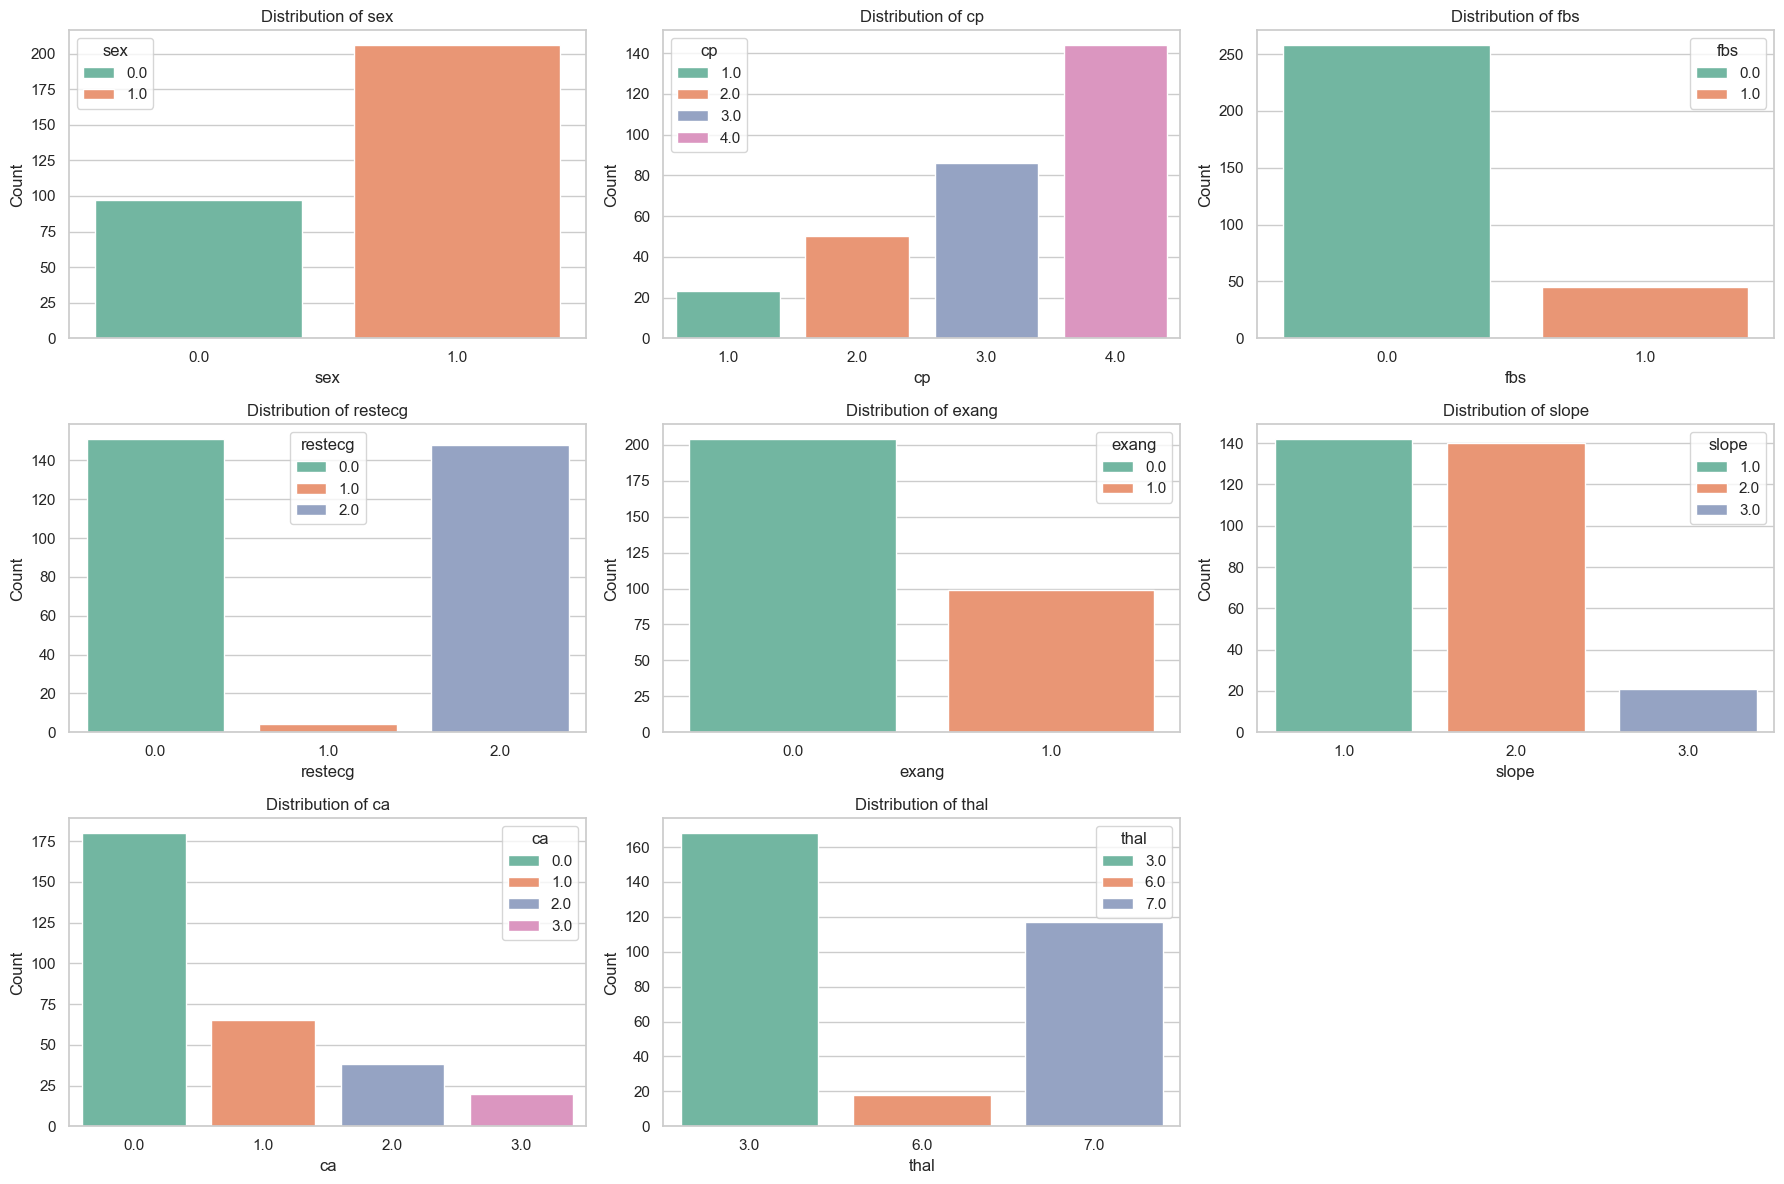

In [41]:
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

plt.figure(figsize=(18, 12))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(x=col, data=df, hue=col, palette='Set2')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
plt.show()

### Insights from Categorical Features

- **sex**: Majority of patients are male (`1`). Both sexes are present, so gender might be a relevant factor.

- **cp (Chest Pain Type)**:
  - Type `4` is most common, followed by `3`.
  - Chest pain type may strongly relate to heart disease and should be studied further with the target variable.

- **fbs (Fasting Blood Sugar > 120 mg/dl)**:
  - Majority have `fbs = 0` (i.e., <= 120).
  - It is highly imbalanced, may not contribute much in classification without further analysis.

- **restecg (Resting ECG Results)**:
  - Values `0` and `2` dominate. Very few patients have value `1`.
  - Some ECG abnormalities exist and might correlate with disease.

- **exang (Exercise Induced Angina)**:
  - Majority have `exang = 0` (no angina).
  - Angina during exercise could be a strong negative signal for heart health.

- **slope (Slope of Peak Exercise ST Segment)**:
  - Values `1` and `2` are common; very few patients have `3`.
  - Slope pattern may give important clues in model training.

- **ca (Number of Major Vessels Colored)**:
  - `ca = 0` is most frequent.
  - Most patients have 0 vessels colored by fluoroscopy → normal heart vessels.

- **thal (Thalassemia type)**:
  - Most common are `3` and `7`, which correspond to **normal**, **fixed**, and **reversible** defects.

---

###  Categorical Features vs Target

Objective:
Visualize how each categorical feature affects the likelihood of heart disease (target).

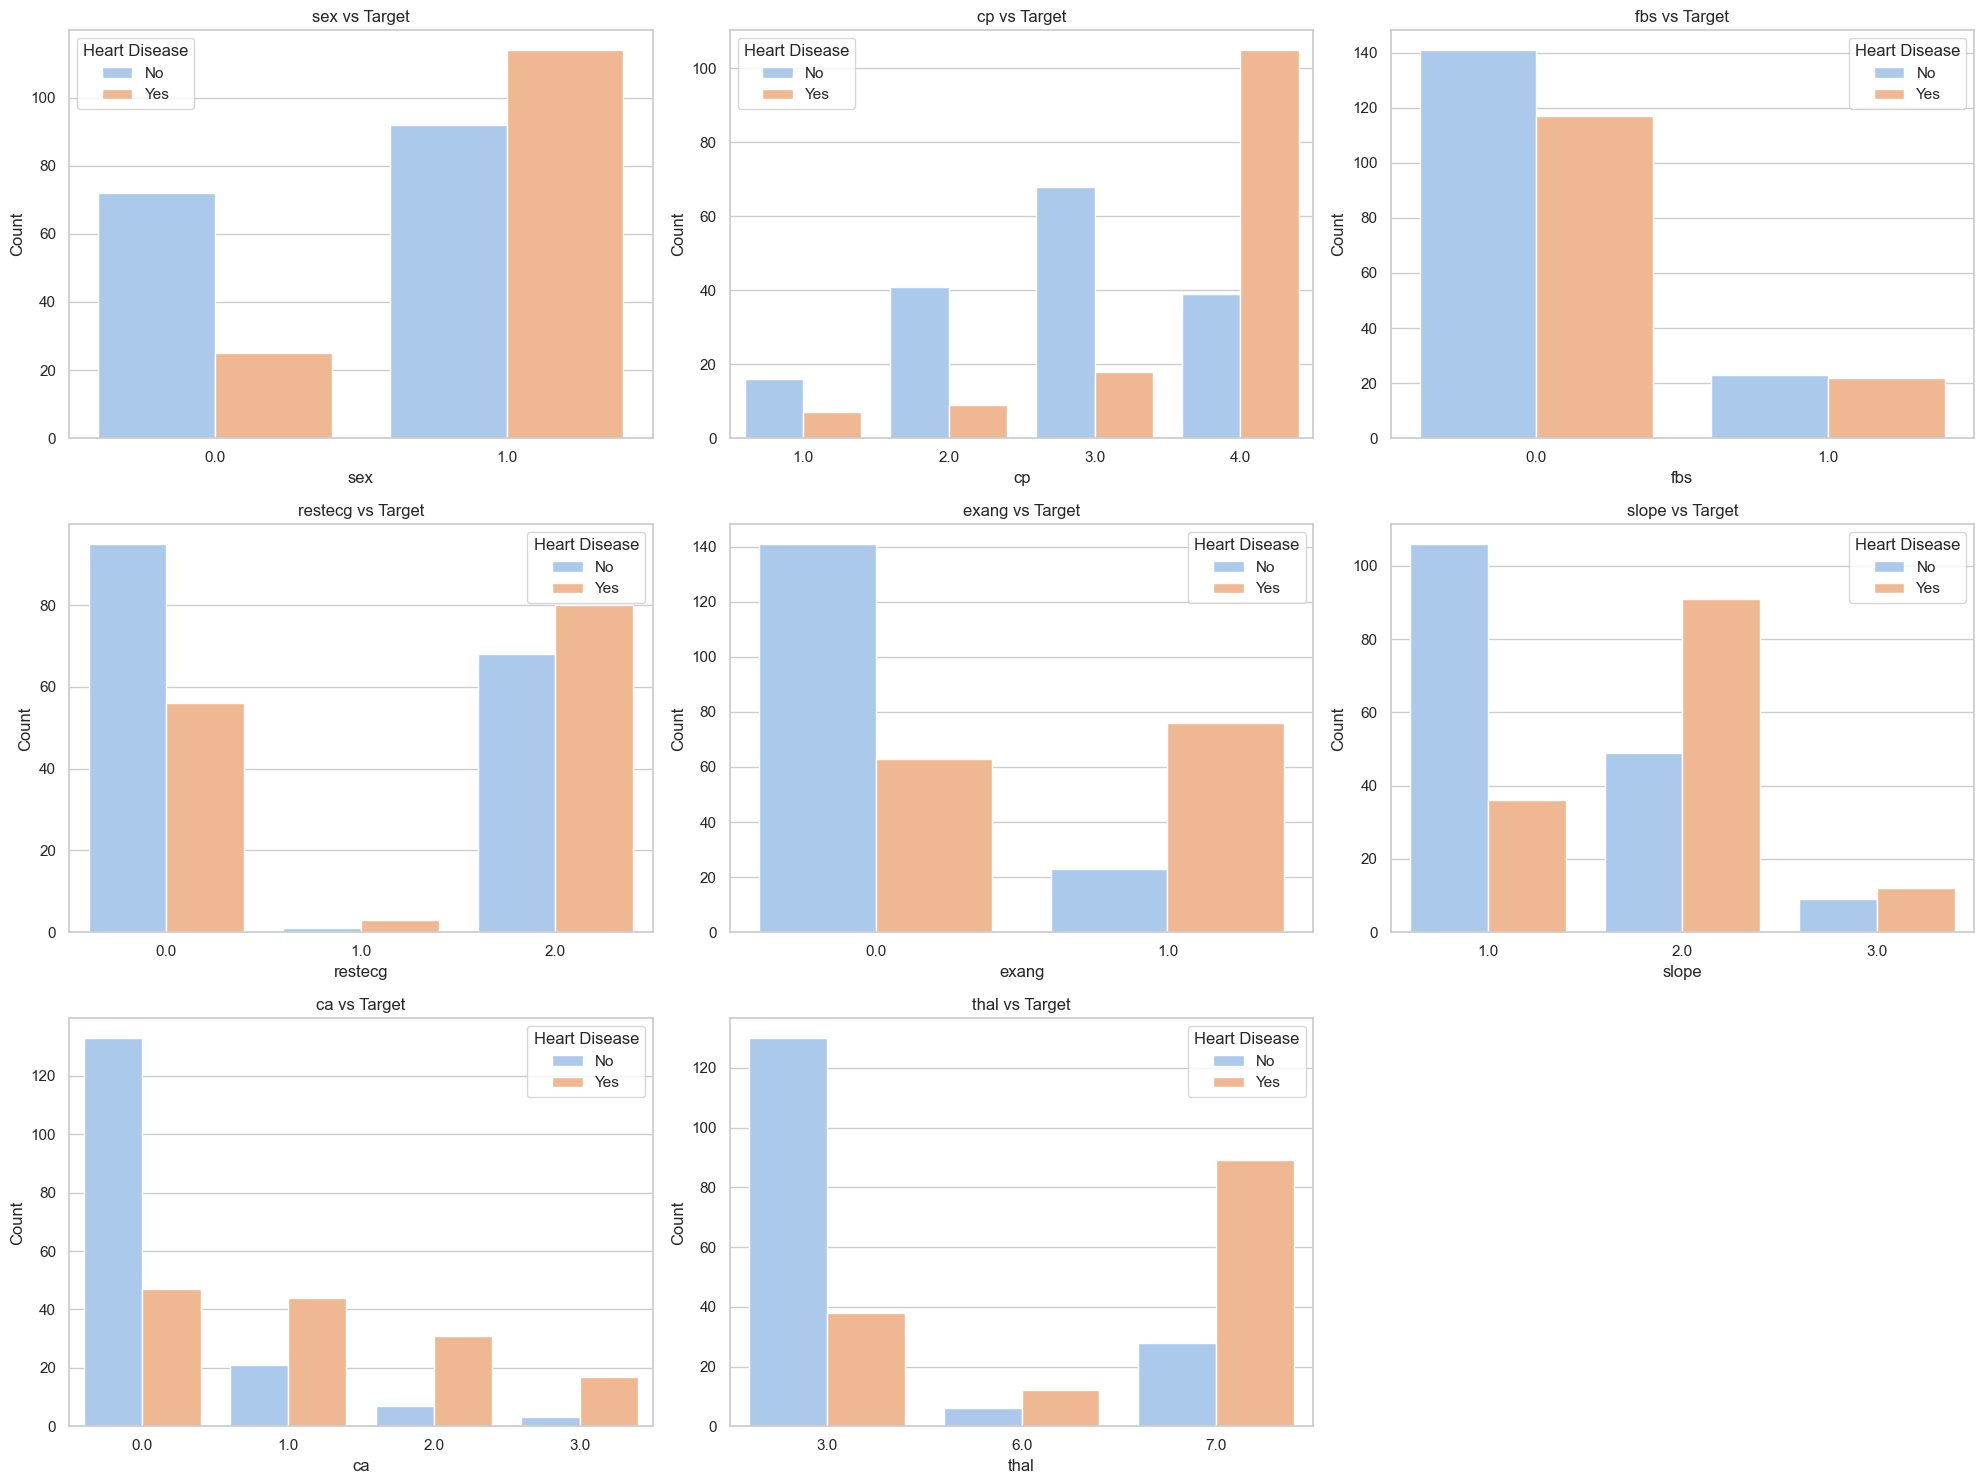

In [42]:
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

plt.figure(figsize=(20, 15))
for i, col in enumerate(cat_cols):
    plt.subplot(3, 3, i+1)
    sns.countplot(data=df, x=col, hue='target', palette='pastel')
    plt.title(f'{col} vs Target')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.legend(title='Heart Disease', labels=['No', 'Yes'])
    
plt.tight_layout()
plt.show()

1. Sex vs Target
 - More males (1.0) in both groups, but females (0.0) show slightly higher heart disease rates proportionally.

2. Chest Pain Type (cp)
 - cp=4 (asymptomatic) is strongly associated with heart disease.

 - cp=3 (non-anginal) also has many cases with no heart disease.

 - Very useful feature for classification!

3. Fasting Blood Sugar (fbs)
 - Mostly 0 (normal), and doesn't show strong separation between target classes.

 - Might be less important in model.

4. Resting ECG (restecg)
 - restecg=2 appears often in both classes; minimal difference in contribution.

5. Exercise Induced Angina (exang)
 - exang=1 is more common in people with heart disease – a useful indicator.

6. Slope of Peak ST (slope)
 - slope=2 is strongly linked with heart disease.

 - slope=1 appears more in those without heart disease.

7. Number of Major Vessels (ca)
 - ca=0 people often have heart disease.

 - Higher values (e.g. ca=3) indicate lower heart disease.

8. Thalassemia (thal)
 - thal=7 (reversible defect) is more common in people with heart disease.

 - thal=3 is more common in people without heart disease

---

### Numerical Features vs Target

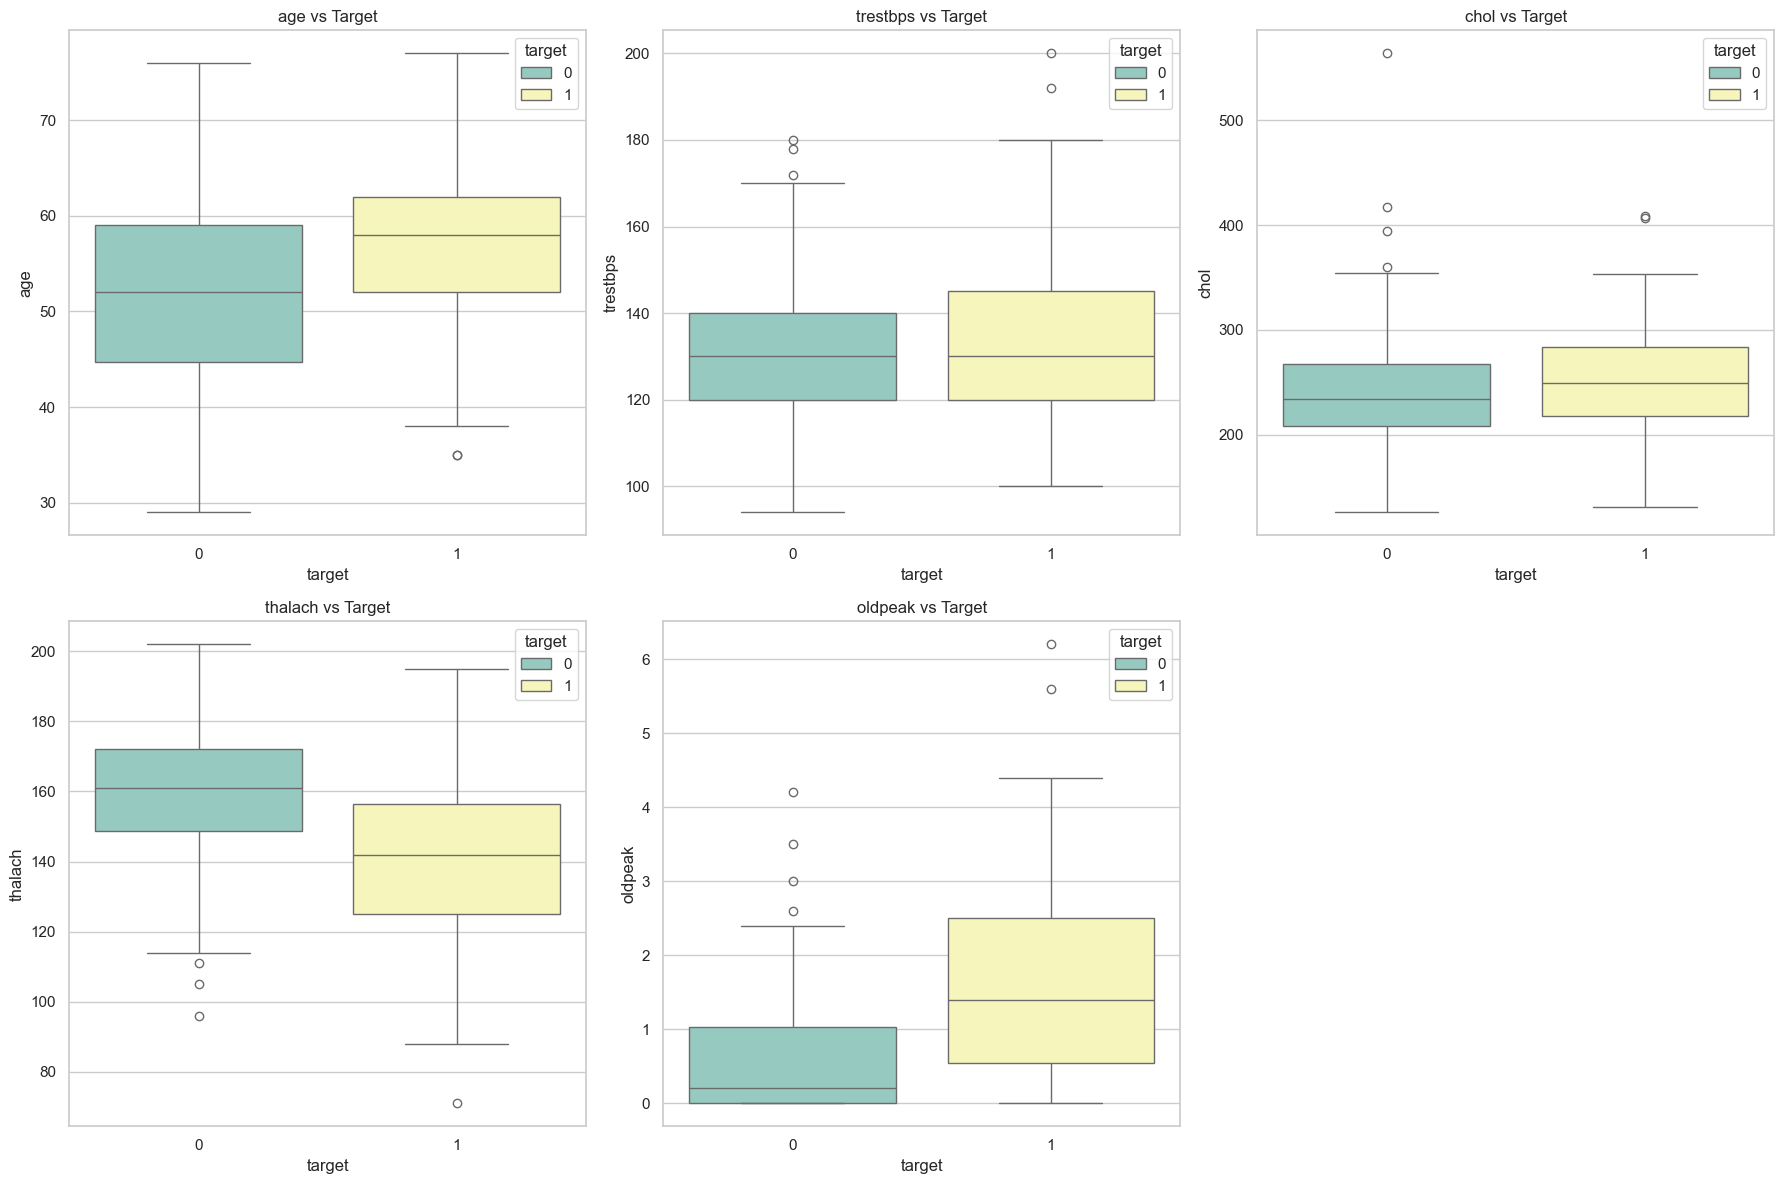

In [44]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
plt.figure(figsize=(18, 12))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i+1)
    sns.boxplot(data=df, x='target', y=col, hue='target', palette='Set3')
    plt.title(f'{col} vs Target')
plt.tight_layout()
plt.show()

### Numerical Features vs Heart Disease

1. age vs target 
 - Median age is slightly higher for people with heart disease.

 - But overlap is large, so age alone may not be a strong predictor.

2. trestbps (resting BP) vs target
 - Distributions are quite similar across both target classes.

 - Minor increase in spread for target = 1.

 - Conclusion: Likely a weak or less influential feature.

3. chol (cholesterol) vs target
 - Wide distribution in both classes, with many outliers.

 - No clear separation in median or spread.

 - Conclusion: Not strongly predictive alone, but may work well in combination with other features.

4. thalach (maximum heart rate achieved) vs target
 - Clear difference between groups:

 - Patients without heart disease have higher heart rate (higher median and upper whisker).

 - Conclusion: Good predictive power — this is a useful feature.

5. oldpeak (ST depression) vs target
 - Patients with heart disease have higher oldpeak values.

 - Spread and outliers are also higher in target = 1 group.

 - Conclusion: Strong correlation — keep this feature!

---

### Correlation Matrix

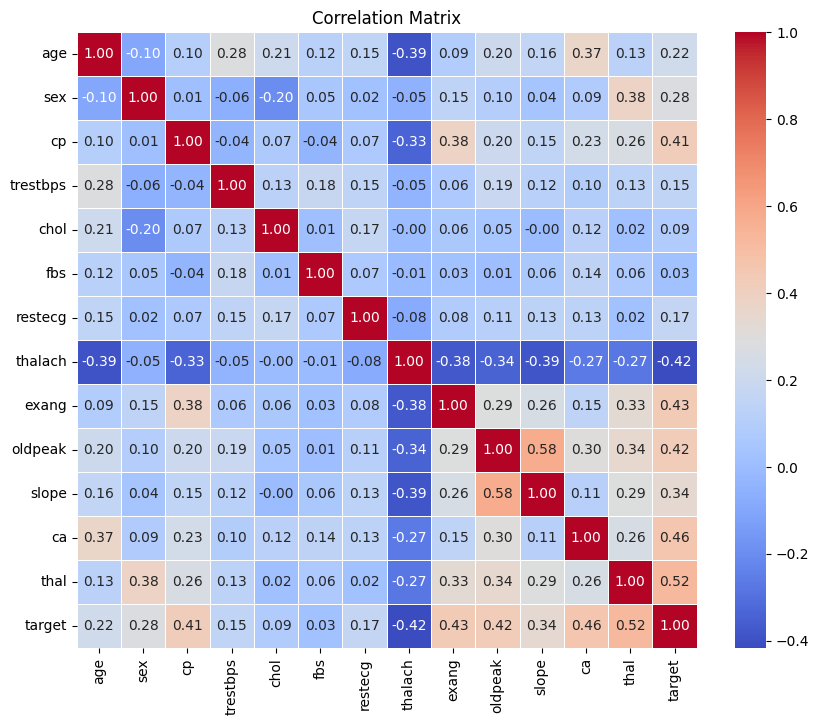

In [6]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5 )
plt.title('Correlation Matrix')
plt.show()

### Correlation Matrix Insights (Feature vs Target)

### Top Features Positively Correlated with `target` (Heart Disease Presence)

| Feature  | Correlation | Interpretation |
|----------|-------------|----------------|
| `thal`   | **+0.52**   | Thalassemia condition is highly indicative of heart disease. |
| `ca`     | **+0.46**   | Number of major vessels colored by fluoroscopy is strongly associated with disease. |
| `exang`  | **+0.43**   | Exercise-induced angina is more common in patients with heart disease. |
| `cp`     | **+0.41**   | Certain chest pain types (like type 4) are positively linked with disease presence. |

---

### Top Features Negatively Correlated with `target`

| Feature     | Correlation | Interpretation |
|-------------|-------------|----------------|
| `thalach`   | **-0.42**   | People with heart disease tend to have lower maximum heart rates. |
| `oldpeak`   | **-0.34**   | ST depression (induced by exercise) is lower in healthy individuals. |

---

### Other Notable Feature Relationships

| Feature Pair         | Correlation | Insight |
|----------------------|-------------|---------|
| `exang` vs `oldpeak` | **+0.58**   | Higher ST depression is often found in those with exercise-induced angina. |
| `cp` vs `exang`      | **+0.38**   | Chest pain type and exercise angina are moderately related. |
| `ca` vs `thal`       | **+0.26**   | Related vessel and thalassemia abnormalities.

---

### Features Weakly Correlated with `target` (Linear Relationship)

These features have low correlation (< ±0.2), suggesting weak individual predictive power:

- `age`: +0.22  
- `chol`: +0.09  
- `fbs`: +0.03  
- `restecg`: +0.17  
- `trestbps`: +0.15  

➡ These may still be useful in multivariate models but are less informative alone.

---



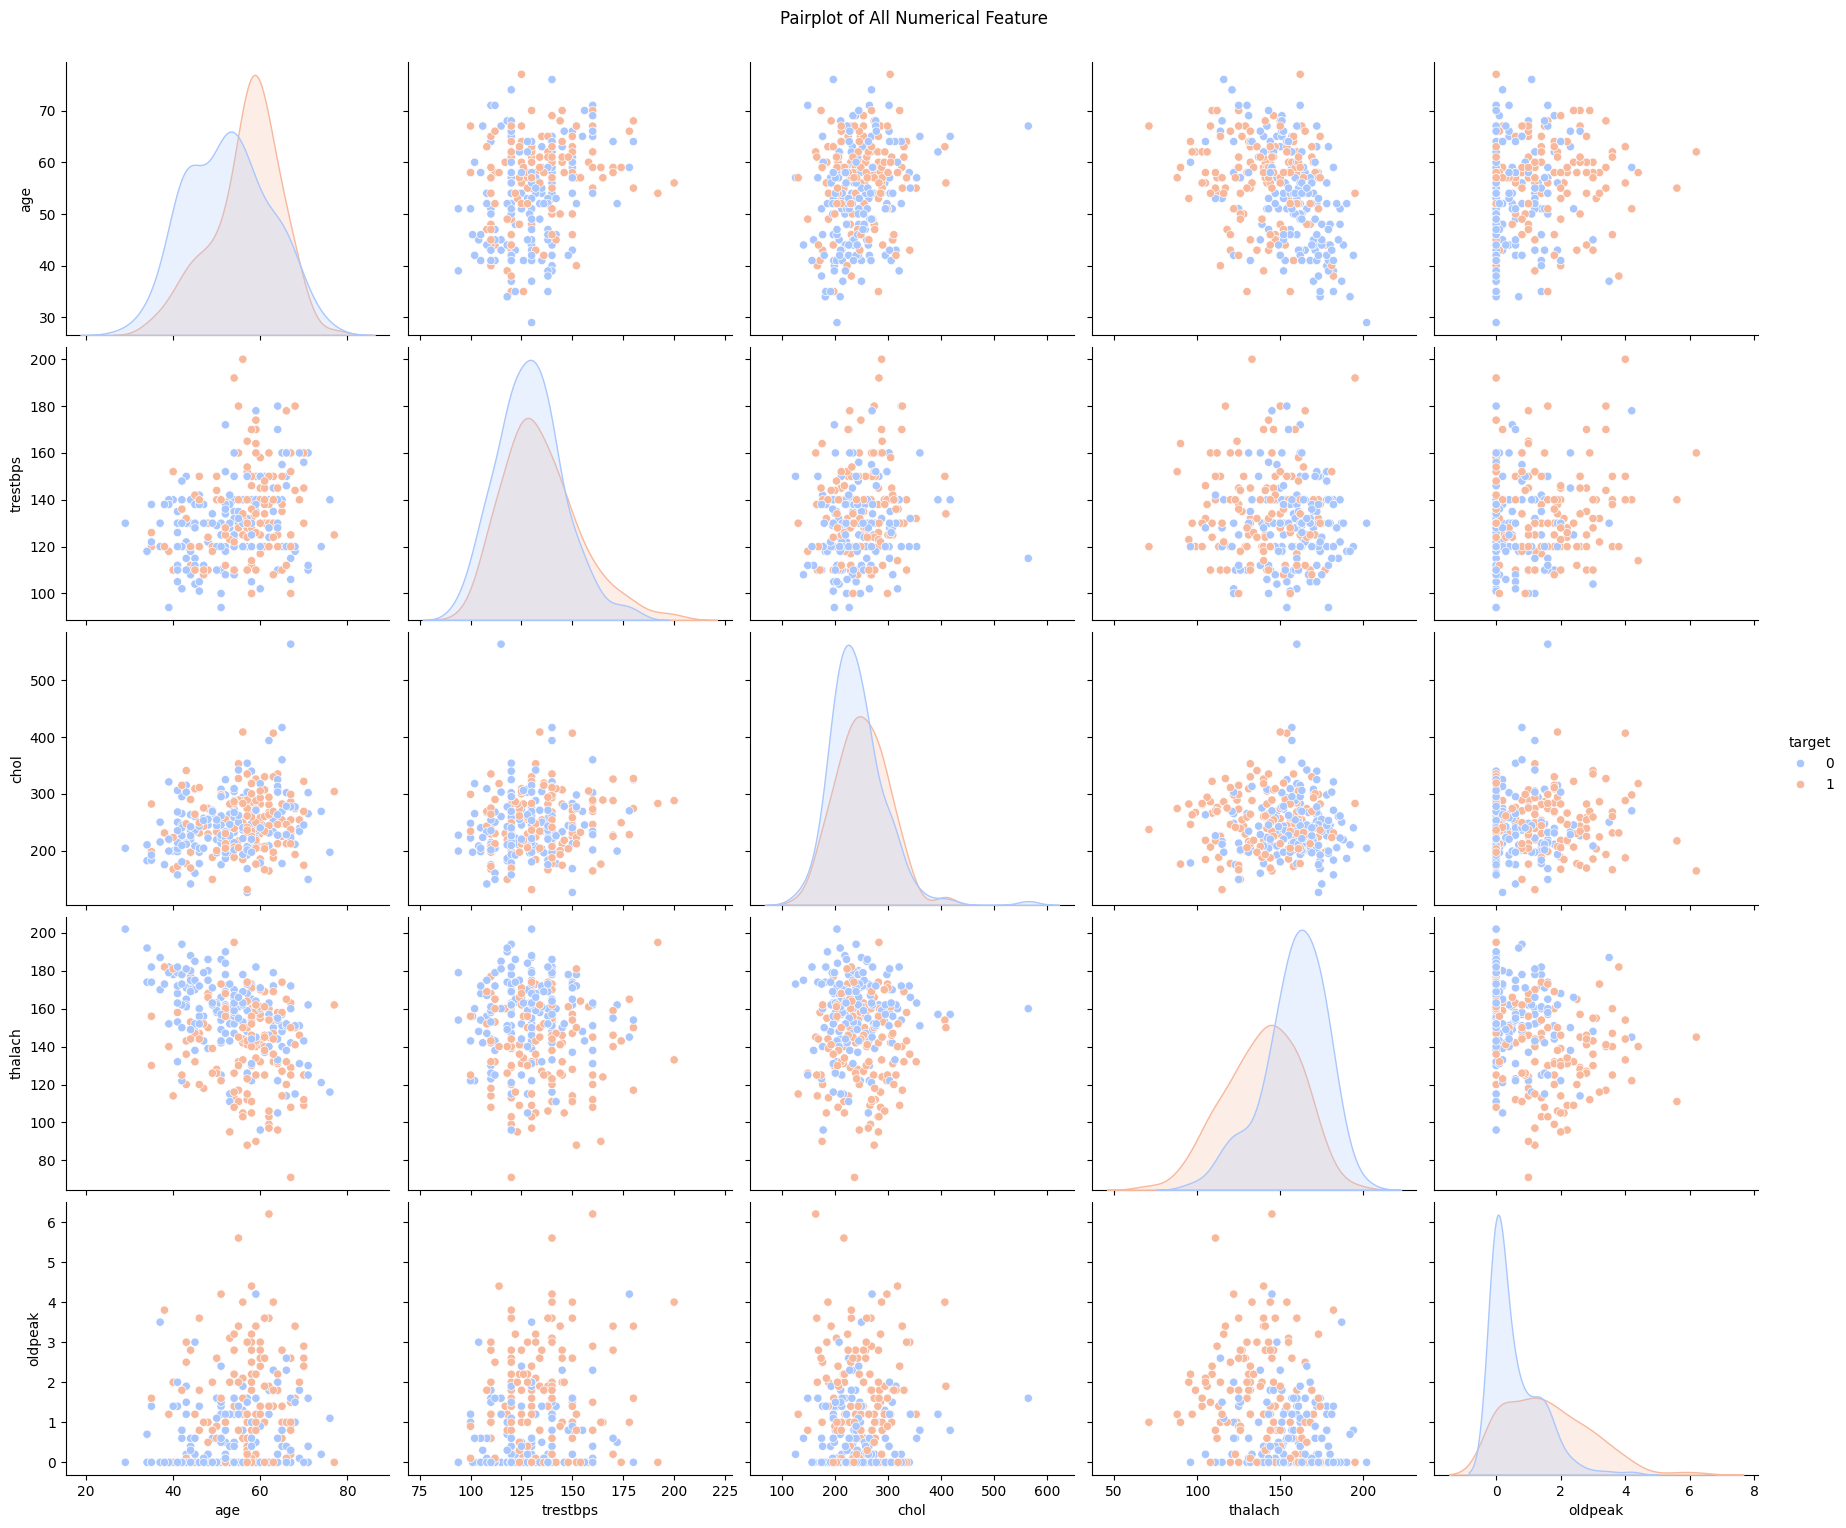

In [13]:
numerical_feature = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']
plt.Figure(figsize=(8,6))
sns.pairplot(df[numerical_feature], hue='target', palette='coolwarm', diag_kind='kde', height=3, aspect=1.2 )
plt.suptitle('Pairplot of All Numerical Feature', y=1.02)
plt.show()

1. **Age Distribution:** Both classes show similar age distributions, mostly concentrated between 40-70 years, with slight overlap throughout the range.

2. **Blood Pressure (trestbps):** Shows a roughly normal distribution around 120-140 mmHg for both classes, with significant overlap between the two groups.

3. **Cholesterol (chol):** Displays a wide range (roughly 100-600 mg/dL) with most values clustering between 200-300. Both classes show similar distributions.

4. **Maximum Heart Rate (thalach):** This appears to be one of the most discriminative features. Class 0 (blue) tends to have higher maximum heart rates (150-200), while class 1 (orange) shows lower values (100-150), suggesting that lower maximum heart rate may be associated with heart disease.

5. **ST Depression (oldpeak):** Most values cluster near 0, with class 1 (orange) showing more instances of higher oldpeak values (up to 4-6), which could indicate more severe cardiac stress.

**Class Separation:** The variables show varying degrees of class separation, with thalach and oldpeak appearing to be the most discriminative features for distinguishing between the two classes. The moderate overlap between classes suggests this is a realistic medical dataset where clear-cut distinctions aren't always possible.

---

### **Feature Selection Based on EDA**

After performing detailed Exploratory Data Analysis (EDA), we identified and removed features with very weak or redundant correlations with the target variable. This decision is based on both statistical insights (correlation matrix) and domain knowledge.

---

### **Features Dropped**

| Feature   | Corr. with Target | Reason                                                                 |
|-----------|-------------------|------------------------------------------------------------------------|
| `fbs`     | 0.03              | Very weak correlation; binary feature with minimal impact              |
| `chol`    | 0.09              | Weak predictor; likely impacted by medication or measurement variation |
| `restecg` | 0.17              | Static ECG reading; less useful than dynamic exercise test results     |
| `trestbps`| 0.15              | Weak signal; likely affected by medication                             |
| `slope`   | 0.34              | Moderate correlation but highly collinear with `oldpeak` (0.58)        |

---

### **Features Retained**

| Feature    | Corr. with Target | Reason                                                                 |
|------------|-------------------|------------------------------------------------------------------------|
| `age`      | 0.22              | Demographic feature; retained for interpretability                     |
| `sex`      | 0.28              | Important demographic representation                                   |
| `cp`       | 0.41              | Strongest categorical predictor                                        |
| `thalach`  | -0.42             | Strong negative correlation (heart rate)                               |
| `exang`    | 0.43              | Strong binary indicator (exercise-induced angina)                      |
| `oldpeak`  | -0.42             | Strong inverse relation to heart disease presence                      |
| `ca`       | 0.46              | High positive correlation; number of major vessels                     |
| `thal`     | 0.52              | Highest positive correlation; thallium stress test result              |

---

### **Final Decision**

We selected the following 8 features for model building:

```python
features_to_keep = ['age', 'sex', 'cp', 'thalach', 'exang', 'oldpeak', 'ca', 'thal']
features_to_drop = ['fbs', 'chol', 'restecg', 'trestbps', 'slope']
```

This ensures our model  built only on meaningful and non-noisy features.

---


In [14]:
df_model = df.copy()

In [15]:
features_to_drop = ['fbs', 'chol', 'restecg', 'trestbps', 'slope']
df_model.drop(columns=features_to_drop, inplace=True)

In [17]:
df_model.head()

,age,sex,cp,thalach,exang,oldpeak,ca,thal,target
0,63.0,1.0,1.0,150.0,0.0,2.3,0.0,6.0,0
1,67.0,1.0,4.0,108.0,1.0,1.5,3.0,3.0,1
2,67.0,1.0,4.0,129.0,1.0,2.6,2.0,7.0,1
3,37.0,1.0,3.0,187.0,0.0,3.5,0.0,3.0,0
4,41.0,0.0,2.0,172.0,0.0,1.4,0.0,3.0,0


In [18]:
df_model.to_csv('E:/Heart_Disease_predictor/data/processed/heart_disease_model.csv', index=False)

### Final Summary of EDA and Feature Selection

- Conducted detailed exploratory data analysis (EDA) to understand data distribution and relationships.
- Analyzed distribution of numerical and categorical features.
- Investigated class imbalance in the target variable.
- Explored correlation matrix and pairplots to detect multicollinearity and weak predictors.
- Dropped low-correlation or redundant features: `fbs`, `chol`, `restecg`, `trestbps`, `slope`.
- Selected final features for model building:

---